![Banner](../images/09_03_banner_rs_rader.png)


# Sentinel-1 Multitemporal GRD Time Series: Deforestation around the Rohingya Camps (2017)

*Dr.


## Overview

Zia U. Ahmed · Upatta Analytics LLC · uses GeoLattice's `geolattice.rsense` remote sensing subpackage*

In this notebook you will process a 2017 stack of Sentinel-1 GRD scenes over the Rohingya camps in Cox's Bazar, Bangladesh, from calibrated scenes to a co-registered, speckle-filtered and terrain-corrected time series, and use it to map forest clearing with machine-learning classifiers.


## Core concepts

### Learning objectives

1. Build a 2017 Sentinel-1 IW GRDH time series on descending relative orbit 77 over the Rohingya camps at Kutupalong, Balukhali, Camp 4 Extension and Camp 18.
2. Calibrate each scene's area-of-interest window to sigma0 with `read_grd_subset` and that scene's own calibration and noise look-up tables.
3. Co-register every date onto one 10 m UTM grid with `create_stack`, and check each date's offset against the stack mean.
4. Apply the Quegan and Yu multitemporal speckle filter and compare its ENL and edge strength with a single-date Lee filter on stable forest.
5. Measure the ground-control-point geocoding shift against Planetary Computer RTC and Sentinel-2, then register the stack to the RTC grid with `estimate_offset` and `apply_offset`.
6. Build an xarray data cube in decibels, summarise each pixel with before and after 1 August 2017 features, and smooth the series with a Savitzky-Golay filter.
7. Classify non-forest, stable forest and forest cleared during 2017 with Random Forest, XGBoost and an LSTM, using 500 m spatial block cross-validation against the Sentinel-2 reference.

### Data

| Data | Source |
|---|---|
| Sentinel-1 IW GRDH, VV+VH, relative orbit 77 (descending), 2017 | Planetary Computer `sentinel-1-grd` (measurement COGs plus each scene's calibration and noise XML), read remotely |
| Sentinel-1 RTC (terrain-corrected gamma0), same track and dates | Planetary Computer `sentinel-1-rtc` (reference for Step 3) |
| Copernicus DEM GLO-30 | Planetary Computer `cop-dem-glo-30` |
| Sentinel-2 L2A over the same AOI, January-February and November-December 2017 | `../../../../Data/08_remote_sensing/08_02_optical/s2_rohingya_2016_2018/` (downloaded by Notebook 07_02_05, Section 10) |

The radar inputs are read once and cached under `Data/08_remote_sensing/08_03_radar/s1_rohingya_2017/`; later runs reuse them.

### Contents

1. Data
2. The 2017 clearing and the processing chain
3. Setup
4. Area, dates and the Sentinel-1 archive
5. GRD steps on every scene: calibrated windows
6. Co-register the stack
7. Multitemporal speckle filter
8. Terrain correction to a common grid
9. Convert to dB
10. The data cube
11. Temporal features
12. Smoothing
13. Classification
14. Validation
15. Summary and exercises


## The 2017 clearing and the processing chain

In the weeks after 25 August 2017, more than 700,000 Rohingya refugees crossed from Myanmar into
Cox's Bazar, Bangladesh. Kutupalong and Balukhali, modest existing camps, grew within months into
the world's largest refugee settlement. The reserve-forest hillsides around them were cleared for
shelters, firewood and footpaths faster than almost any other land-cover change this notebook
series has looked at. The AOI below covers Camp 4 Extension, Camp 18 and the Balukhali/Moragachhtola
area, matching the screenshot used to define it.

Section 10 of Notebook 07_02_05 followed this clearing with Sentinel-2 and met the limit of optical
monitoring: the influx began in the June-October monsoon, when the AOI is almost always under
cloud. Radar sees through cloud. This notebook builds a **multitemporal Sentinel-1 GRD time series**
for 2017 from the raw GRD products, scene by scene, and turns it into a deforestation map:

| Step | What | Function |
|---|---|---|
| GRD steps 1 to 5 on every scene | Thermal-noise removal and radiometric calibration of each scene's AOI window (Notebook 07_03_01_01), one track, one orbit direction | `rs.sar.read_grd_subset` |
| 1. Co-register the stack | Every scene geocoded onto one common grid (SNAP `CreateStack`) | `rs.sar.create_stack` |
| 2. Multitemporal speckle filter | Quegan & Yu filter across all dates (SNAP `Multi-Temporal-Speckle-Filter`) | `rs.sar.multitemporal_speckle_filter` |
| 3. Terrain correction to a common grid | Register to a DEM-terrain-corrected reference; compare with full RTC | `rs.sar.estimate_offset`, `rs.sar.apply_offset` |
| 4. Convert to dB | After all averaging in linear units | `rs.sar.to_db` |
| 5. Data cube | `xarray` Dataset with a time dimension | `xarray` |
| 6. Temporal features | Mean, median, std, min, max, percentiles, date of minimum VH, amplitude, before/after change | NumPy |
| 7. Smoothing | Savitzky-Golay filter along time | SciPy |
| 8. Classification | Random Forest, XGBoost and an LSTM | scikit-learn, XGBoost, PyTorch |
| 9. Validation | Against an independent Sentinel-2 reference, with spatial cross-validation | scikit-learn |


## Setup

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README.

In [1]:
# show figures inside the notebook
%matplotlib inline
import json  # read the Sentinel-2 item metadata
import time  # timing
import warnings  # warning control
from pathlib import Path  # file paths

warnings.filterwarnings("ignore")  # hide library warnings

import numpy as np  # arrays
import pandas as pd  # tables
import geopandas as gpd  # vector data (the AOI box)
import xarray as xr  # labelled raster cubes
import rioxarray  # noqa: F401
import matplotlib.pyplot as plt  # figures
from shapely.geometry import box  # rectangle geometry
from rasterio.enums import Resampling  # resampling methods
from scipy.signal import savgol_filter  # Savitzky-Golay smoothing filter
import pystac  # read and write saved STAC items
import pystac_client  # STAC search client
import planetary_computer  # signs Planetary Computer URLs
import odc.stac  # load STAC items into xarray

import geolattice.rsense as rs  # GeoLattice remote sensing
from geolattice.rsense.sar import speckle  # speckle filters and ENL

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
DATA = Path("../../../../Data/08_remote_sensing/08_03_radar")  # data folder
CACHE = DATA / "s1_rohingya_2017"  # cache for the downloaded and processed stacks
CACHE.mkdir(parents=True, exist_ok=True)  # create it if needed
OUTPUTS = Path("outputs")  # folder for results
OUTPUTS.mkdir(exist_ok=True)  # create it if needed
# Sentinel-2 scenes of the same area, downloaded by the optical notebook
S2_DIR = Path("../../../../Data/08_remote_sensing/08_02_optical/s2_rohingya_2016_2018")
if not S2_DIR.exists():  # stop with a clear message if they are missing
    # stop with a clear message
    raise FileNotFoundError(f"{S2_DIR} is missing: run Section 10 of Notebook 07_02_05 first")
CRS, RES = "EPSG:32646", 10                       # UTM 46N; 10 m grid, the Sentinel-2 grid of the reference
# GeoLattice version and cache folder
print("geolattice.rsense", rs.__version__ if hasattr(rs, "__version__") else "", "| cache:", CACHE)

geolattice.rsense 0.2.0.dev0 | cache: data/s1_rohingya_2017


## Area, dates and the Sentinel-1 archive

AOI: 21.213115 N, 92.130199 E to 21.179337 N, 92.166669 E (about 14 km²). The three dates split
2017 into a **before** period (1 January to 1 August, pre-influx) and an **after** period
(1 August to 1 December, which contains the influx of 25 August and the months of clearing that
followed).


In [2]:
ROH_DATES = [  # start of the "before" period, the cut-off date, and the end of the "after" period
    "2017-01-01", "2017-08-01", "2017-12-01",
]
ROH_MINLON, ROH_MAXLON = 92.130199, 92.166669  # AOI longitude limits
ROH_MINLAT, ROH_MAXLAT = 21.179337, 21.213115  # AOI latitude limits
# the AOI as a one-polygon GeoDataFrame in WGS 84
ROH_AOI = gpd.GeoDataFrame(geometry=[box(ROH_MINLON, ROH_MINLAT, ROH_MAXLON, ROH_MAXLAT)], crs=4326)
BOUNDS = (ROH_MINLON, ROH_MINLAT, ROH_MAXLON, ROH_MAXLAT)  # the same box as a tuple
INFLUX = pd.Timestamp("2017-08-25")  # the date the refugee influx began
# AOI area and the two periods
print(f"AOI {ROH_AOI.to_crs(CRS).area.iloc[0] / 1e6:.1f} km²; before: {ROH_DATES[0]} to {ROH_DATES[1]}; after: {ROH_DATES[1]} to {ROH_DATES[2]}")

def pc_catalog():  # the Planetary Computer STAC catalogue, opened only when a search is needed
    return pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1", modifier=planetary_computer.sign_inplace)


def pc_href(href):  # a freshly signed URL (saved items keep their old, expired token)
    return planetary_computer.sign(href.split("?")[0])


grd_file = CACHE / "grd_items_2017.json"  # the catalogue search, saved by an earlier run
if grd_file.exists():  # searched before: read the saved items from the local drive
    grd = list(pystac.ItemCollection.from_file(str(grd_file)))
else:  # first run: every Sentinel-1 GRD scene of 2017 over the AOI, sorted by time, then saved
    grd = sorted(pc_catalog().search(collections=["sentinel-1-grd"], bbox=list(BOUNDS), datetime="2017-01-01/2017-12-31").items(),
                 key=lambda i: i.datetime)
    pystac.ItemCollection(grd).save_object(str(grd_file))  # keep it for the next run
# one row per scene: track, pass, platform, polarisations and date
archive = pd.DataFrame([{"track": i.properties["sat:relative_orbit"], "pass": i.properties["sat:orbit_state"],
                         "platform": i.properties["platform"], "pols": "+".join(i.properties["sar:polarizations"]),
                         "date": i.datetime.date()} for i in grd])
# scenes per track and pass, with first and last date
archive.groupby(["track", "pass", "platform", "pols"]).date.agg(["count", "min", "max"])

AOI 14.2 km²; before: 2017-01-01 to 2017-08-01; after: 2017-08-01 to 2017-12-01


count         min         max
track pass       platform    pols                                
41    ascending  SENTINEL-1A VV         2  2017-01-13  2017-02-06
                             VV+VH     25  2017-02-18  2017-12-27
77    descending SENTINEL-1A VV+VH     20  2017-01-03  2017-12-29
                 SENTINEL-1B VV+VH      1  2017-06-02  2017-06-02

Planetary Computer holds 48 GRD scenes over the AOI for 2017 on two relative orbits:

- **Ascending track 41:** 27 scenes, but the first two (13 January and 6 February) are VV only.
- **Descending track 77:** 20 Sentinel-1A scenes and one Sentinel-1B scene, all VV+VH, from
  3 January to 29 December.

A time series must come from **one relative orbit**: every scene then has the same viewing
geometry, so differences between dates are changes on the ground, not in incidence angle or look
direction. Track 77 covers the whole window in both polarisations. Sentinel-1B flies the same
orbits as 1A, so its one scene joins the series.


In [3]:
TRACK = 77  # use one relative orbit (track) so every scene has the same geometry
# dual-pol scenes of that track within the study period
items = [i for i in grd if i.properties["sat:relative_orbit"] == TRACK
         and ROH_DATES[0] <= str(i.datetime.date()) <= ROH_DATES[2] and "VH" in i.properties["sar:polarizations"]]
# acquisition times (UTC, timezone removed)
times = pd.to_datetime([i.datetime for i in items], utc=True).tz_convert(None)
# label each date as before or after the cut-off
period = np.where(times < pd.Timestamp(ROH_DATES[1]), "before", "after")
# number of scenes in each period
print(f"track {TRACK}: {len(items)} dual-pol scenes; before {np.sum(period == 'before')}, after {np.sum(period == 'after')}")
# the dates of each period
print(pd.Series(times.strftime("%d %b"), index=period).groupby(level=0).agg(", ".join).to_string())

track 77: 19 dual-pol scenes; before 13, after 6
after        07 Aug, 31 Aug, 24 Sep, 30 Oct, 11 Nov, 23 Nov
before    03 Jan, 27 Jan, 20 Feb, 04 Mar, 16 Mar, 09 Apr...


## GRD steps on every scene: calibrated windows

Notebook 07_03_01_01 took one GRD scene through the full chain. Here the same steps run on every
scene, but only on the AOI. `read_grd_subset` locates the AOI in each scene's radar geometry with
the scene's own ground control points (GCPs), reads just that window from the remote
Cloud-Optimized GeoTIFF (about 0.6 MB instead of ~600 MB per polarisation), and applies thermal-noise
removal and calibration to sigma0 with the scene's own calibration and noise look-up tables,
sampled at the window's true position in the scene.


19 scenes x 2 polarisations read and calibrated in 150 s


,scene,window (rows x cols),seconds
0,S1A_IW_GRDH_1SDV_20170103T234805_20170103T2348...,512x522,7.4
1,S1A_IW_GRDH_1SDV_20170127T234804_20170127T2348...,512x522,6.5
2,S1A_IW_GRDH_1SDV_20170220T234811_20170220T2348...,512x523,6.1


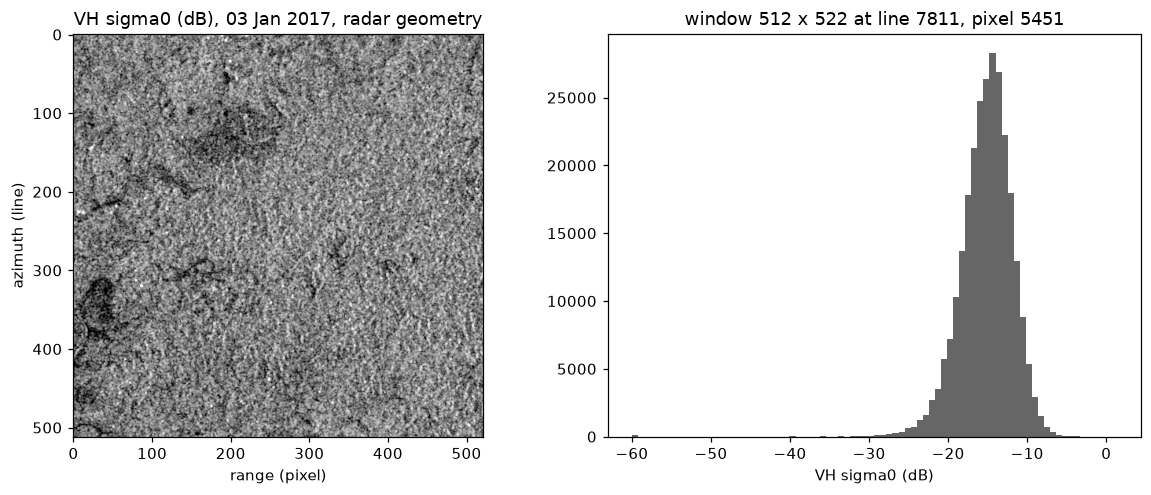

In [4]:
def read_scenes():  # read and calibrate every scene
    scenes, rows = {"vv": [], "vh": []}, []  # calibrated windows per polarisation, and a log
    for it in items:  # loop over the scenes
        t0 = time.perf_counter()  # time each scene
        for pol in ("vv", "vh"):  # both polarisations
            # read only the window around the AOI, calibrate to sigma0 and remove thermal noise
            scenes[pol].append(rs.sar.read_grd_subset(
                pc_href(it.assets[pol].href), pc_href(it.assets[f"schema-calibration-{pol}"].href),
                pc_href(it.assets[f"schema-noise-{pol}"].href),
                bounds=BOUNDS, margin=40))
        # window size and run time
        rows.append({"scene": it.id, "window (rows x cols)": "x".join(map(str, scenes["vh"][-1]["window"][2:])),
                     "seconds": round(time.perf_counter() - t0, 1)})
    return scenes, pd.DataFrame(rows)  # return the scenes and the log as a table

stack_file = CACHE / f"grd_sigma0_track{TRACK}_2017.nc"  # the processed stack is cached as NetCDF
if stack_file.exists():  # reuse it when present
    print("Reusing", stack_file)  # the cached stack will be loaded instead
    scenes = None  # the individual scenes are not needed then
else:
    t0 = time.perf_counter()  # start the timer
    scenes, read_log = read_scenes()  # read and calibrate all scenes
    # total run time
    print(f"{len(items)} scenes x 2 polarisations read and calibrated in {time.perf_counter() - t0:.0f} s")
    display(read_log.head(3))  # first three rows of the log
    s = scenes["vh"][0]  # the first VH scene
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))  # two panels
    # VH sigma0 in dB, still in radar geometry
    ax[0].imshow(rs.sar.to_db(s["data"]), cmap="gray", vmin=-25, vmax=-5)
    # title and axis labels
    ax[0].set_title(f"VH sigma0 (dB), {times[0]:%d %b %Y}, radar geometry"); ax[0].set_xlabel("range (pixel)"); ax[0].set_ylabel("azimuth (line)")
    # histogram of the VH values
    ax[1].hist(rs.sar.to_db(s["data"][np.isfinite(s["data"])]).ravel(), bins=80, color="0.4")
    # label and title
    ax[1].set_xlabel("VH sigma0 (dB)"); ax[1].set_title(f"window {s['window'][2]} x {s['window'][3]} at line {s['window'][0]}, pixel {s['window'][1]}")
    plt.tight_layout(); plt.show()  # arrange and draw

In radar geometry the image is mirrored and skewed relative to a map: a descending pass flies
south and looks west, and pixels are spaced in slant-range time and azimuth time, not metres on the
ground. The next step puts every date on the same map grid.

## Co-register the stack

SNAP's `CreateStack` co-registers images of one track to a master. The simpler route the workflow
allows, and the one used here, is to geocode every scene directly onto **one common grid**: then
all dates land on identical pixels by construction. `create_stack` builds a north-up 10 m UTM grid
over the AOI and warps each scene onto it with the GCPs surrounding its window. To check the
result, each date is registered against the stack's temporal mean: a perfectly co-registered stack
gives offsets of zero.


In [5]:
if stack_file.exists():  # cached stack
    stack = xr.open_dataset(stack_file).load()  # load it into memory
    stack = stack.rio.write_crs(CRS)  # attach the CRS
else:
    # resample every scene onto one 10 m UTM grid and stack them along time
    stack = xr.Dataset({pol: rs.sar.create_stack(scenes[pol], times, bounds=BOUNDS, crs=CRS, resolution=RES, name=pol)
                        for pol in ("vv", "vh")})
    # record where the data came from
    stack.attrs.update({"source": "Planetary Computer sentinel-1-grd", "track": TRACK, "calibration": "sigma0, noise removed"})
    # save the stack (without the CRS helper variable)
    stack.drop_vars("spatial_ref", errors="ignore").to_netcdf(stack_file)
# dimensions, CRS and units
print(dict(stack.sizes), "| CRS", stack.rio.crs, "| units:", stack.vh.attrs.get("units"))

mean_vv = rs.sar.to_db(stack.vv.mean("time"))  # temporal mean of VV in dB, the registration target
# shift of each date against the mean (within 5 pixels)
offsets = [rs.sar.estimate_offset(rs.sar.to_db(stack.vv.isel(time=k)), mean_vv, max_shift=5, smooth=5)
           for k in range(stack.sizes["time"])]
# offsets as a table
co = pd.DataFrame(offsets, columns=["dy", "dx", "correlation"], index=times.strftime("%Y-%m-%d"))
# range of offsets and correlations
print(f"offsets of each date against the temporal mean: dy in {sorted(co.dy.unique())}, dx in {sorted(co.dx.unique())}; "
      f"correlation {co.correlation.min():.2f}-{co.correlation.max():.2f}")

{'time': 19, 'y': 377, 'x': 382} | CRS EPSG:32646 | units: linear


offsets of each date against the temporal mean: dy in [np.int64(0)], dx in [np.int64(-1), np.int64(0), np.int64(1)]; correlation 0.63-0.74


The stack holds 19 dates on one 377 × 382 grid of 10 m pixels. Registered against the stack's own
temporal mean, every date has a north-south offset of 0 and an east-west offset of at most one
pixel (10 m), with correlations of 0.63 to 0.74 (speckle keeps single dates from correlating more
closely). The dates are co-registered with each other to within a pixel. Whether the stack sits in
the right place on the ground is a different question, answered in Step 3.

The classes used to check the processing (and, in Step 8, to train and test the models) come from
the Sentinel-2 reference of Notebook 07_02_05 on the same grid:

- **non-forest:** 276 ha;
- **stable forest:** 465 ha;
- **forest cleared during 2017:** 561 ha;
- **unlabelled:** 9.6% of the area (cloud or missing data in either period).

## Multitemporal speckle filter

A single-image filter (Lee, Refined Lee, Gamma-MAP; Notebook 07_03_01_01) estimates each pixel
from its neighbours in one image, so it must trade speckle for spatial detail. The **Quegan and Yu
(2001) multitemporal filter** also uses the other dates:

**J_k(x) = E\[I_k\](x) / N · Σ_i I_i(x) / E\[I_i\](x)**

where E[·] is a local spatial mean. Each date keeps its own local level E[I_k], while the speckle
pattern, which is independent between dates, averages out over the N ratios, reducing it by up to
√N. We compare it with a single-date Lee filter of the same 7 × 7 window on a homogeneous patch of
stable forest (Equivalent Number of Looks, ENL = mean² / variance: higher is smoother) and on how
well each preserves the mean backscatter and edges.


In [6]:
def s2_ndvi(day, grid):  # Sentinel-2 NDVI of one date, used as an independent reference
    "Cloud-masked Sentinel-2 NDVI of one date on the radar grid (two MGRS tiles mosaicked)."
    # the Sentinel-2 folders of that date
    dirs = [p for p in S2_DIR.iterdir() if p.is_dir() and json.loads((p / "item.json").read_text())["properties"]["datetime"][:10] == day]
    layers = {}  # one layer per band
    for band in ("red", "nir", "scl"):  # red, NIR and the scene classification layer (SCL)
        # each tile reprojected onto the radar grid (nearest for classes, average for reflectance)
        tiles = [rioxarray.open_rasterio(p / f"{band}.tif").squeeze("band", drop=True).rio.write_nodata(0)
                 .rio.reproject_match(grid, resampling=Resampling.nearest if band == "scl" else Resampling.average)
                 for p in dirs]
        cube = xr.concat(tiles, "tile")  # stack the tiles
        # mosaic: maximum over tiles, ignoring zeros
        layers[band] = cube.max("tile") if band == "scl" else cube.where(cube > 0).max("tile")
    red, nir = layers["red"] / 1e4, layers["nir"] / 1e4               # 2017: processing baseline < 04.00, no offset
    # NDVI, kept only where SCL says vegetation, bare soil or water (classes 4-6)
    return ((nir - red) / (nir + red)).where(layers["scl"].isin([4, 5, 6]))

grid = stack.vh.isel(time=0)  # the radar grid (first date)
# median NDVI of two dry-season dates before the influx
ndvi_before = xr.concat([s2_ndvi(d, grid) for d in ("2017-01-09", "2017-02-08")], "t").median("t")
# median NDVI of two dates at the end of 2017
ndvi_after = xr.concat([s2_ndvi(d, grid) for d in ("2017-11-20", "2017-12-15")], "t").median("t")
forest_before, forest_after = (ndvi_before > 0.5).values, (ndvi_after > 0.5).values  # forest = NDVI above 0.5
observed = np.isfinite(ndvi_before.values) & np.isfinite(ndvi_after.values)  # pixels seen in both periods
labels = np.full(grid.shape, -1)  # -1 = unlabelled
labels[observed & ~forest_before] = 0                                  # non-forest already in Jan-Feb 2017
labels[observed & forest_before & forest_after] = 1                    # forest, both periods
labels[observed & forest_before & ~forest_after] = 2                   # forest cleared during 2017
CLASSES = {0: "non-forest", 1: "stable forest", 2: "cleared forest"}  # class codes -> names
px_ha = RES * RES / 1e4  # hectares per pixel
# area of each class
print({CLASSES[k]: f"{(labels == k).sum() * px_ha:.0f} ha" for k in CLASSES}, f"| unlabelled {np.mean(labels < 0):.1%}")

{'non-forest': '276 ha', 'stable forest': '465 ha', 'cleared forest': '561 ha'} | unlabelled 9.6%


,ENL on stable forest (mean over dates),mean VH (dB of linear mean),"edge strength (mean |gradient|, dB/pixel)"
filter,,,
unfiltered,3.78,-13.57,0.68
"Lee 7x7, single date",17.73,-13.60,0.27
Quegan multitemporal 7x7,9.06,-13.61,0.66


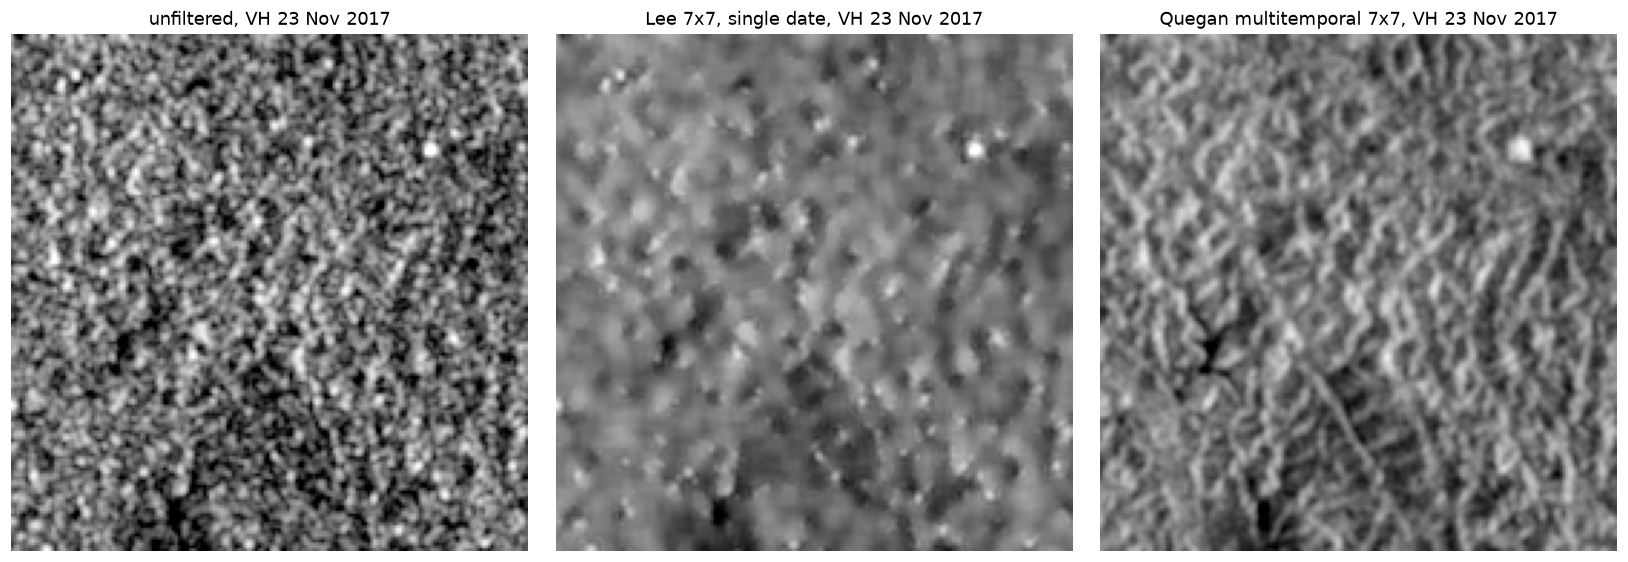

In [7]:
# Lee filter applied to each date on its own
lee_single = xr.apply_ufunc(lambda a: np.asarray(speckle.lee(a, 7)), stack.vh, input_core_dims=[["y", "x"]],
                            output_core_dims=[["y", "x"]], vectorize=True)
# Quegan multitemporal filter: uses all dates together
quegan = rs.sar.multitemporal_speckle_filter(stack, spatial="boxcar", size=7)

# the most homogeneous 21 x 21 patch of stable forest
from scipy.ndimage import uniform_filter  # moving-window mean
share = uniform_filter((labels == 1).astype(float), 21)  # share of stable-forest pixels in each 21 x 21 window
# centre of the window with the most stable forest
cy, cx = np.unravel_index(np.argmax(np.where(np.isfinite(stack.vh.isel(time=0)), share, 0)), share.shape)
patch = (slice(cy - 10, cy + 11), slice(cx - 10, cx + 11))  # the 21 x 21 patch around it
rows = []  # one row per filter
# the three versions of the stack
for name, img in [("unfiltered", stack.vh), ("Lee 7x7, single date", lee_single), ("Quegan multitemporal 7x7", quegan.vh)]:
    # mean ENL over the dates in the forest patch
    enl = np.mean([speckle.enl_estimate(img.isel(time=k).values[patch]) for k in range(img.sizes["time"])])
    # ENL, mean backscatter and edge strength
    rows.append({"filter": name, "ENL on stable forest (mean over dates)": enl,
                 "mean VH (dB of linear mean)": float(rs.sar.to_db(np.nanmean(img.values))),
                 "edge strength (mean |gradient|, dB/pixel)": float(np.nanmean(np.abs(np.gradient(rs.sar.to_db(img.mean("time").values))[1])))})
filt = pd.DataFrame(rows).set_index("filter")  # as a table
display(filt.round(2))  # show it

k = int(np.argmin(np.abs(times - pd.Timestamp("2017-11-23"))))  # the date closest to 23 November 2017
zoom = (slice(80, 260), slice(80, 260))  # a 180 x 180 pixel zoom
fig, ax = plt.subplots(1, 3, figsize=(15, 5))  # three panels
# one panel per version
for a, (name, img) in zip(ax, [("unfiltered", stack.vh), ("Lee 7x7, single date", lee_single), ("Quegan multitemporal 7x7", quegan.vh)]):
    # the zoom of this version on that date, with title
    a.imshow(rs.sar.to_db(img.isel(time=k).values)[zoom], cmap="gray", vmin=-22, vmax=-8); a.set_title(f"{name}, VH {times[k]:%d %b %Y}"); a.set_axis_off()
plt.tight_layout(); plt.show()  # arrange and draw

The unfiltered stack has an ENL of 3.8 over the most homogeneous patch of stable forest, close to
the nominal 4.4 of IW GRDH.

| Filter | ENL | Mean VH | Edge strength |
|---|---|---|---|
| Unfiltered | 3.8 | −13.57 dB | 0.68 dB/pixel |
| Lee 7 × 7, single date | 17.7 | −13.60 dB | 0.27 dB/pixel |
| Quegan multitemporal 7 × 7 | 9.1 | −13.61 dB | 0.66 dB/pixel |

The single-date Lee filter smooths more, but it erases spatial detail: the mean gradient falls from
0.68 to 0.27 dB per pixel. The Quegan filter more than doubles the ENL while keeping almost all of
the edges, the shelters, paths and clearing boundaries this study is about. Both preserve the mean
backscatter to within 0.04 dB. Step 8 shows what this is worth: without speckle filtering the
classification loses about 11 percentage points of accuracy.

## Terrain correction to a common grid

The stack is co-registered *with itself* (Step 1), but is it in the right place on the ground?
Geocoding from GCPs places each pixel using the GCPs' heights, interpolated between points about
20 km apart, rather than a DEM, and the camps sit on hills. Full **terrain correction**
(range-Doppler with a DEM) needs the orbit state vectors and the complete product annotation, which
Planetary Computer's GRD files do not carry (Notebook 07_03_01_01, Section 5). Planetary Computer
does publish the same acquisitions already terrain-corrected with a DEM, as **RTC** gamma0. We use
it as the geometric reference: measure where the GCP-geocoded stack sits relative to it and to the
Sentinel-2 reference, then register the stack to it.


In [8]:
# cached Planetary Computer RTC (terrain-corrected gamma0) stack
rtc_file = CACHE / f"rtc_gamma0_track{TRACK}_2017.nc"
if rtc_file.exists():  # reuse it when present
    rtc = xr.open_dataset(rtc_file).load()  # load it
else:
    # RTC scenes of the same track and period
    rtc_items = sorted([i for i in pc_catalog().search(collections=["sentinel-1-rtc"], bbox=list(BOUNDS),
                                                       datetime=f"{ROH_DATES[0]}/{ROH_DATES[2]}").items()
                        if i.properties["sat:relative_orbit"] == TRACK], key=lambda i: i.datetime)
    x, y = stack.x.values, stack.y.values  # the GRD stack's grid coordinates
    # load VV and VH on that grid, one image per day
    rtc = odc.stac.load(rtc_items, bands=["vv", "vh"], crs=CRS, resolution=RES, x=(x.min() - 5, x.max() + 5),
                        y=(y.min() - 5, y.max() + 5), groupby="solar_day").interp(x=x, y=y, method="nearest")
    rtc = rtc.where(rtc > 0)  # zero means no data
    rtc["time"] = pd.to_datetime(rtc.time.values)  # plain datetime values
    rtc.drop_vars("spatial_ref", errors="ignore").to_netcdf(rtc_file)  # cache the stack
# confirm the RTC dates match the GRD dates
print(f"RTC: {rtc.sizes['time']} dates on the same grid; dates match the GRD stack: "
      f"{bool((pd.to_datetime(rtc.time.values).normalize() == times.normalize()).all())}")

dem_file = CACHE / "copdem30_stack_grid.nc"  # the DEM on the stack grid, cached like the stacks
if dem_file.exists():  # reuse it when present
    dem = xr.open_dataarray(dem_file).load()  # load it
else:
    # Copernicus 30 m DEM tiles over the AOI
    dem_items = list(pc_catalog().search(collections=["cop-dem-glo-30"], bbox=list(BOUNDS)).items())
    # load the DEM onto the stack grid
    dem = odc.stac.load(dem_items, bands=["data"], crs=CRS, resolution=RES, x=(stack.x.min().item() - 5, stack.x.max().item() + 5),
                        y=(stack.y.min().item() - 5, stack.y.max().item() + 5)).data.isel(time=0).interp(x=stack.x, y=stack.y)
    dem.drop_vars(["spatial_ref", "time"], errors="ignore").to_netcdf(dem_file)  # cache it
slope = np.degrees(np.arctan(np.hypot(*np.gradient(dem.values, RES))))  # slope in degrees from the DEM gradient
# elevation and slope ranges
print(f"terrain: {float(dem.min()):.0f} to {float(dem.max()):.0f} m, median slope {np.nanmedian(slope):.0f} deg, 95th percentile {np.nanpercentile(slope, 95):.0f} deg")

grd_mean = rs.sar.to_db(quegan.vh.mean("time"))  # mean VH of the filtered GRD stack, dB
rtc_mean = rs.sar.to_db(rtc.vh.mean("time"))  # mean VH of the RTC stack, dB
# three comparisons: GRD vs RTC, and each against Sentinel-2 NDVI
checks = {"GCP-geocoded GRD stack vs RTC": (grd_mean, rtc_mean),
          "GCP-geocoded GRD stack vs Sentinel-2 NDVI (Jan-Feb)": (grd_mean, ndvi_before),
          "RTC vs Sentinel-2 NDVI (Jan-Feb)": (rtc_mean, ndvi_before)}
# offset and correlation of each pair (search within 30 pixels)
reg = pd.DataFrame([dict(zip(["dy (rows)", "dx (cols)", "correlation"], rs.sar.estimate_offset(a, b, max_shift=30)), comparison=n)
                    for n, (a, b) in checks.items()]).set_index("comparison")
# offsets in metres
reg["offset (m)"] = [f"{abs(r['dy (rows)']) * RES} N-S, {abs(r['dx (cols)']) * RES} E-W" for _, r in reg.iterrows()]
reg  # show the table

RTC: 19 dates on the same grid; dates match the GRD stack: True


terrain: 0 to 44 m, median slope 9 deg, 95th percentile 23 deg


,dy (rows),dx (cols),correlation,offset (m)
comparison,,,,
GCP-geocoded GRD stack vs RTC,4,19,0.794575,"40.0 N-S, 190.0 E-W"
GCP-geocoded GRD stack vs Sentinel-2 NDVI (Jan-Feb),4,20,0.559327,"40.0 N-S, 200.0 E-W"
RTC vs Sentinel-2 NDVI (Jan-Feb),0,1,0.543083,"0.0 N-S, 10.0 E-W"


applied offset dy=4, dx=19 pixels; remaining offset (0, 0), correlation with RTC 0.10 -> 0.78


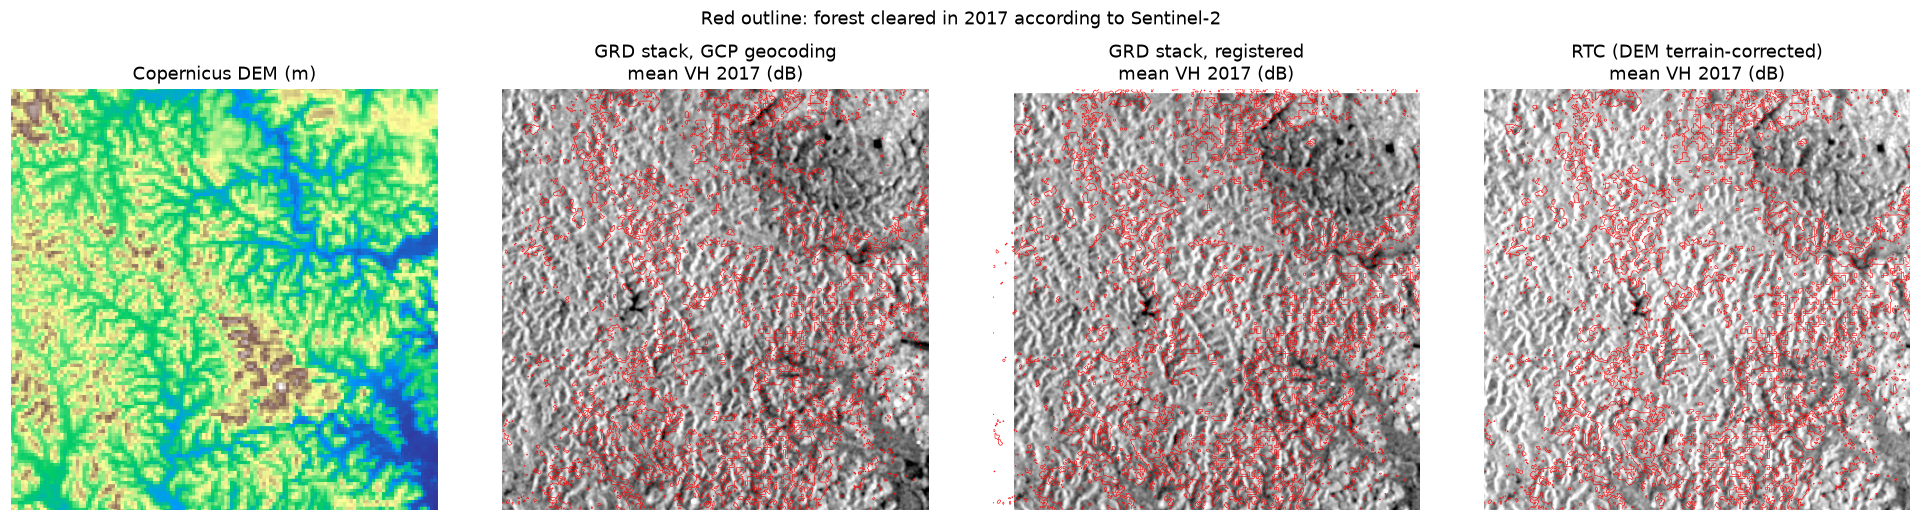

In [9]:
DY, DX = int(reg.iloc[0]["dy (rows)"]), int(reg.iloc[0]["dx (cols)"])  # the GRD-vs-RTC offset in pixels
stack_tc = rs.sar.apply_offset(quegan, DY, DX)  # shift the filtered stack by that offset
# offset that remains after the shift
after = rs.sar.estimate_offset(rs.sar.to_db(stack_tc.vh.mean("time")), rtc_mean, max_shift=5)
# correlation with RTC before the shift
r0 = np.corrcoef(*[np.nan_to_num(v.values.ravel(), nan=np.nanmean(v.values)) for v in (grd_mean, rtc_mean)])[0, 1]
# applied offset and the improvement
print(f"applied offset dy={DY}, dx={DX} pixels; remaining offset {after[:2]}, correlation with RTC {r0:.2f} -> {after[2]:.2f}")

fig, ax = plt.subplots(1, 4, figsize=(18, 4.6))  # four panels
ax[0].imshow(dem, cmap="terrain"); ax[0].set_title("Copernicus DEM (m)")  # the DEM
# the GRD stack before and after registration, and the RTC
for a, img, title in [(ax[1], grd_mean, "GRD stack, GCP geocoding"), (ax[2], rs.sar.to_db(stack_tc.vh.mean("time")), "GRD stack, registered"),
                      (ax[3], rtc_mean, "RTC (DEM terrain-corrected)")]:
    a.imshow(img, cmap="gray", vmin=-20, vmax=-10); a.set_title(f"{title}\nmean VH 2017 (dB)")  # mean VH in dB
    a.contour(labels == 2, levels=[0.5], colors="r", linewidths=0.4)  # outline of the forest cleared in 2017
for a in ax:  # no axes
    a.set_axis_off()  # no axes
# title, arrange and draw
plt.suptitle("Red outline: forest cleared in 2017 according to Sentinel-2", y=1.02); plt.tight_layout(); plt.show()

The terrain is low but rugged: 0 to 44 m, with a median slope of 9° and 5% of slopes above 23°. The
registration checks:

| Comparison | Offset |
|---|---|
| GCP-geocoded stack vs RTC | 40 m north-south, 190 m east-west |
| GCP-geocoded stack vs Sentinel-2 | 40 m north-south, 200 m east-west |
| RTC vs Sentinel-2 | within one pixel (10 m) |

The error is therefore in the GCP geocoding, not in RTC or Sentinel-2. Descending Sentinel-1 looks
west, so placing pixels without the DEM displaces them mostly east-west. The 190 m is a bulk
offset, larger than terrain heights of a few tens of metres alone would explain; it comes from
interpolating between GCPs about 20 km apart.

Shifting the stack by (4, 19) pixels removed the offset: the correlation with RTC rose from 0.10 to
0.78, and the remaining offset is zero. The figure shows the result: after registration the
Sentinel-2 clearing outlines fall on the same valleys and ridges in the GRD stack as in RTC.
Registration fixes the bulk shift; terrain-dependent displacement inside the AOI, at most tens of
metres here, remains. Full range-Doppler terrain correction (`process_grd(backend="sarsen")` or
SNAP, with a complete SAFE download) would remove it.

## Convert to dB

Every average so far (calibration, geocoding, filtering, temporal means) was taken in **linear**
units. Only now are the values converted to decibels, for analysis and as model features: dB makes
the skewed backscatter distribution nearly symmetric and turns ratios into differences.


In [10]:
cube_lin = stack_tc  # the registered, filtered stack in linear units
lin_mean = float(rs.sar.to_db(np.nanmean(cube_lin.vh.values)))  # dB of the linear mean
db_mean = float(np.nanmean(rs.sar.to_db(cube_lin.vh.values)))  # mean of the dB values
# the same gap on the unfiltered stack
raw_bias = float(rs.sar.to_db(np.nanmean(stack.vh.values))) - float(np.nanmean(rs.sar.to_db(stack.vh.values)))
# filtering shrinks the gap between the two averages
print(f"VH: dB of the linear mean {lin_mean:.2f} dB; mean of dB values {db_mean:.2f} dB "
      f"(difference {lin_mean - db_mean:.2f} dB after filtering, {raw_bias:.2f} dB on the unfiltered stack)")

VH: dB of the linear mean -13.59 dB; mean of dB values -14.09 dB (difference 0.50 dB after filtering, 0.84 dB on the unfiltered stack)


Averaging the dB values instead of the linear values would bias the mean VH low by 0.50 dB on the
filtered stack and by 0.84 dB on the unfiltered one, as large as some of the changes this notebook
measures. The filtered stack's bias is smaller because filtering already removed part of the
speckle spread that causes it.

## The data cube

The cube is one `xarray` Dataset with a time dimension: VV and VH in dB, their difference (the
VV/VH ratio in dB, which rises where volume scattering from canopy is lost), and the period of each
date. Plotting the cube's mean per Sentinel-2 class shows the signal the rest of the notebook uses.


<xarray.Dataset> Size: 34MB
Dimensions:      (time: 19, y: 377, x: 382)
Coordinates:
  * time         (time) datetime64[us] 152B 2017-01-03T23:48:17.860528 ... 20...
    period       (time) <U6 456B 'before' 'before' 'before' ... 'after' 'after'
  * y            (y) float64 3kB 2.346e+06 2.346e+06 ... 2.342e+06 2.342e+06
  * x            (x) float64 3kB 4.097e+05 4.097e+05 ... 4.135e+05 4.135e+05
    label        (y, x) int64 1MB 1 1 1 1 1 1 1 1 1 1 ... 1 1 1 0 0 0 0 0 -1 -1
    spatial_ref  int64 8B 0
Data variables:
    vv           (time, y, x) float32 11MB nan nan nan ... -8.069 -8.373 -8.65
    vh           (time, y, x) float32 11MB nan nan nan ... -16.11 -15.51 -14.85
    ratio        (time, y, x) float32 11MB nan nan nan nan ... 8.045 7.14 6.199
Attributes:
    units:    dB
    track:    77
    steps:    noise removal, sigma0, CreateStack, Quegan 7x7, registered to R...


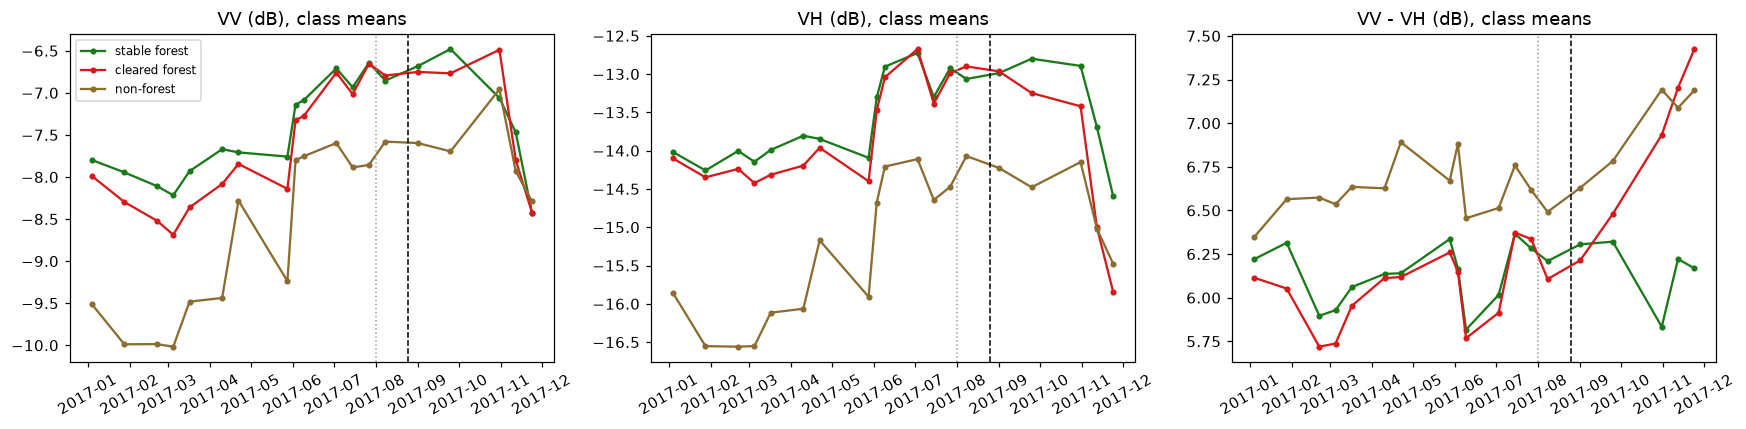

In [11]:
cube = xr.Dataset({"vv": rs.sar.to_db(cube_lin.vv), "vh": rs.sar.to_db(cube_lin.vh)})  # the data cube in dB
cube["ratio"] = cube.vv - cube.vh  # VV minus VH (the cross-polarisation ratio in dB)
# add the period of each date and the class of each pixel as coordinates
cube = cube.assign_coords(period=("time", period), label=(("y", "x"), labels))
# record units and processing steps
cube.attrs.update({"units": "dB", "track": TRACK, "steps": "noise removal, sigma0, CreateStack, Quegan 7x7, registered to RTC, dB"})
cube.drop_vars("spatial_ref", errors="ignore").to_netcdf(OUTPUTS / "s1_rohingya_2017_cube.nc")  # save the cube
print(cube)  # show its structure

fig, ax = plt.subplots(1, 3, figsize=(16, 4))  # three panels
for a, var in zip(ax, ["vv", "vh", "ratio"]):  # one panel per variable
    for k, colour in [(1, "#1a7a1a"), (2, "#d7191c"), (0, "#8c6d31")]:
        # mean of the variable over the pixels of one class, per date
        s = cube[var].where(cube.label == k).mean(("y", "x")).to_series()
        a.plot(s.index, s.values, "o-", ms=3, color=colour, label=CLASSES[k])  # class time series
    # mark the influx date and the period cut-off
    a.axvline(INFLUX, color="k", ls="--", lw=1); a.axvline(pd.Timestamp(ROH_DATES[1]), color="0.6", ls=":", lw=1)
    # title and rotated date labels
    a.set_title(f"{var.upper() if var != 'ratio' else 'VV - VH'} (dB), class means"); a.tick_params(axis="x", rotation=30)
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()  # legend, arrange and draw

The class means tell the story of 2017:

- **The monsoon (June to October)** raises VV and VH by about 1 to 1.5 dB in all classes: wet soil and
  canopy scatter more. This is why a single before/after image pair from different seasons
  misleads.
- **Before the influx,** forest that would be cleared and forest that would survive have almost the
  same VH. The future clearings already have lower VV (0.2 to 0.5 dB) from January to April, consistent with
  more open, degraded forest near the existing camps.
- **After the influx,** the VV − VH ratio of cleared forest climbs steadily from September: 6.1 dB in
  August to 7.4 dB by 23 November. Stable forest stays near 6.2 dB. Losing the canopy removes the
  volume scattering that keeps VH high, and shelters add bright VV double-bounce.
- **In November** VH of cleared forest falls about 1.2 dB below stable forest. Non-forest starts
  lowest in VV and VH and keeps the highest ratio.

## Temporal features

Each pixel's time series is summarised by features that do not depend on the exact dates: the mean,
median, standard deviation, minimum, maximum, 10th and 90th percentiles, the amplitude of change
(90th minus 10th percentile), the day of year of the minimum VH, and, because the question is about
an event, the mean before and after 1 August and their difference.


34 features per pixel: vv_mean, vv_median, vv_std, vv_min, vv_max, vv_p10, vv_p90, vv_amplitude, vv_before, vv_after, vv_change, vh_mean ...


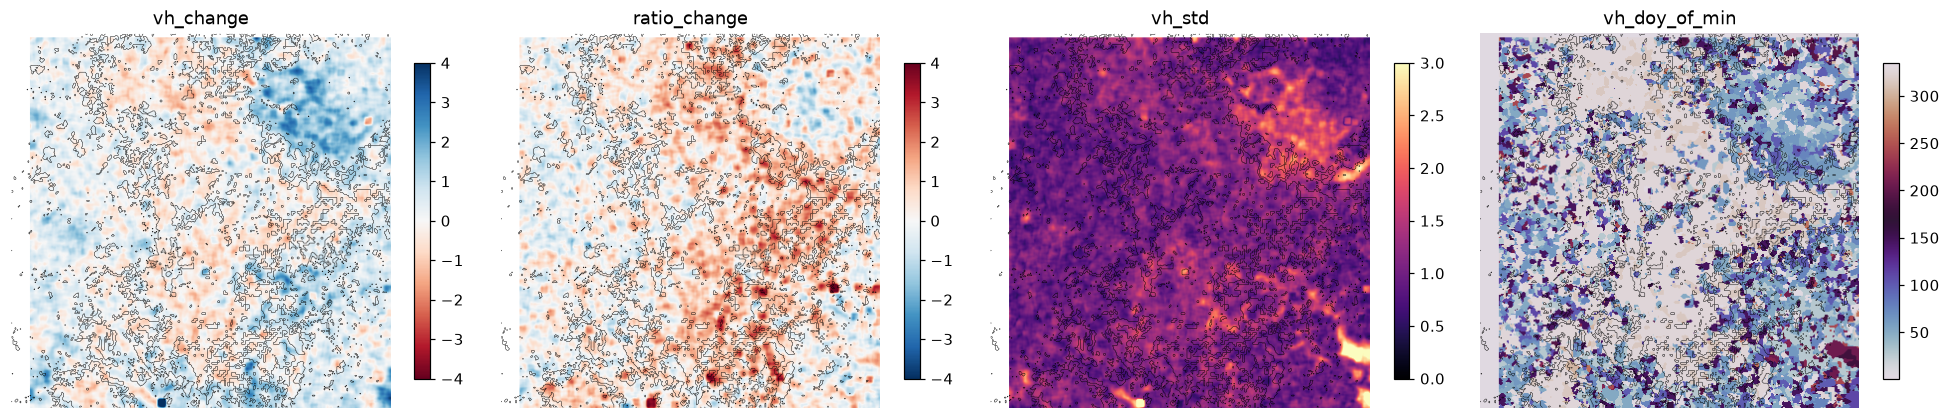

                vh_change  ratio_change  vh_std
label                                          
non-forest           0.83          0.23    1.25
stable forest        0.28          0.03    0.94
cleared forest      -0.12          0.64    1.12


In [12]:
def temporal_features(cube, period):  # per-pixel temporal features from the cube
    doy = np.array([t.dayofyear for t in pd.to_datetime(cube.time.values)])  # day of year of each date
    before, after = period == "before", period == "after"  # masks of the two periods
    F = {}  # feature name -> 2-D array
    for var in ("vv", "vh", "ratio"):  # VV, VH and their ratio
        a = cube[var].values  # the variable as an array (time, y, x)
        # mean, median and standard deviation over time
        F[f"{var}_mean"], F[f"{var}_median"], F[f"{var}_std"] = np.nanmean(a, 0), np.nanmedian(a, 0), np.nanstd(a, 0)
        F[f"{var}_min"], F[f"{var}_max"] = np.nanmin(a, 0), np.nanmax(a, 0)  # minimum and maximum
        # 10th and 90th percentile
        F[f"{var}_p10"], F[f"{var}_p90"] = np.nanpercentile(a, 10, 0), np.nanpercentile(a, 90, 0)
        F[f"{var}_amplitude"] = F[f"{var}_p90"] - F[f"{var}_p10"]  # robust range
        # mean before and after the cut-off
        F[f"{var}_before"], F[f"{var}_after"] = np.nanmean(a[before], 0), np.nanmean(a[after], 0)
        F[f"{var}_change"] = F[f"{var}_after"] - F[f"{var}_before"]  # change between the periods
    vh = cube.vh.values  # VH values
    # day of year of the lowest VH
    F["vh_doy_of_min"] = doy[np.nanargmin(np.where(np.isfinite(vh), vh, np.inf), 0)].astype("float32")
    # features as a Dataset on the image grid
    return xr.Dataset({k: (("y", "x"), v.astype("float32")) for k, v in F.items()}, coords={"y": cube.y, "x": cube.x})

features = temporal_features(cube, period)  # compute the features
# number and names of the features
print(f"{len(features.data_vars)} features per pixel:", ", ".join(list(features.data_vars)[:12]), "...")
fig, ax = plt.subplots(1, 4, figsize=(18, 4.4))  # four panels
# four features with their colour maps and limits
for a, (var, cmap, lim) in zip(ax, [("vh_change", "RdBu", (-4, 4)), ("ratio_change", "RdBu_r", (-4, 4)),
                                    ("vh_std", "magma", (0, 3)), ("vh_doy_of_min", "twilight", (1, 335))]):
    # show the feature
    im = a.imshow(features[var], cmap=cmap, vmin=lim[0], vmax=lim[1]); a.set_title(var); a.set_axis_off()
    # outline of the cleared forest and a colour bar
    a.contour(labels == 2, levels=[0.5], colors="k", linewidths=0.3); fig.colorbar(im, ax=a, shrink=0.7)
plt.tight_layout(); plt.show()  # arrange and draw
# median of three features per class
print(features[["vh_change", "ratio_change", "vh_std"]].to_dataframe().assign(label=labels.ravel())
      .query("label >= 0").drop(columns="spatial_ref", errors="ignore").groupby("label").median().rename(index=CLASSES).round(2))

34 features summarise each pixel's year. The medians per class show which ones separate the classes:

- **`ratio_change`** (after minus before, VV − VH): +0.64 dB for cleared forest, against +0.03 for
  stable forest and +0.23 for non-forest.
- **`vh_change`:** −0.12 dB for cleared forest, against +0.28 for stable forest.

In the maps, the cleared areas outlined from Sentinel-2 show up as negative VH change and positive
ratio change. The date of minimum VH (the twilight-coloured map) falls late in the year where the
clearing happened, because VH there ended the year at its lowest.

## Smoothing

Even after the multitemporal filter, each date carries residual noise (speckle, soil moisture,
rain on the canopy). A **Savitzky-Golay** filter fits a low-order polynomial in a moving window
along time; with a window of 5 acquisitions and order 2 it keeps step changes better than a plain
moving average.


mean |change between consecutive dates| in VH: {'filtered cube': '0.99 dB', '+ Savitzky-Golay': '0.53 dB'}


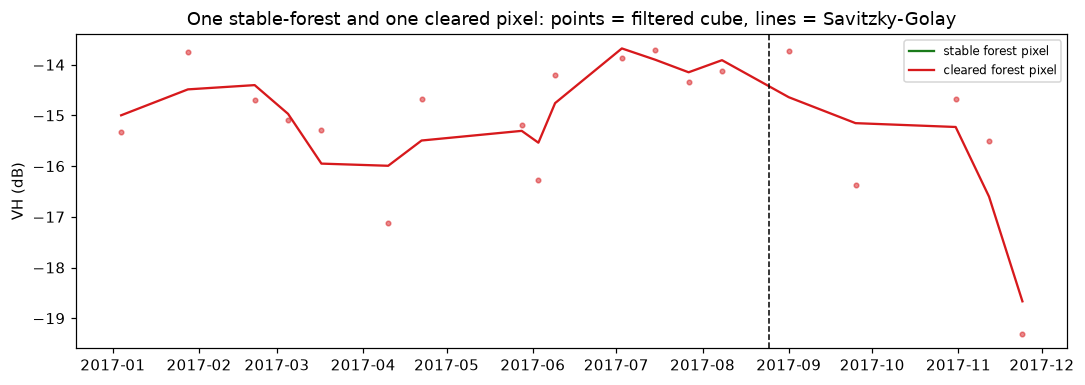

In [13]:
def savgol_cube(cube, window=5, order=2):  # smooth each pixel's time series with a Savitzky-Golay filter
    out = cube.copy()  # copy the cube
    for var in ("vv", "vh", "ratio"):  # each variable
        a = cube[var].values  # values (time, y, x)
        # fill gaps with the pixel's mean so the filter can run
        filled = np.where(np.isfinite(a), a, np.nanmean(a, axis=0, keepdims=True))
        # filter along time
        out[var] = (cube[var].dims, savgol_filter(filled, window, order, axis=0).astype("float32"))
    return out  # return the smoothed cube

cube_sg = savgol_cube(cube)  # smooth the cube
# mean absolute change between consecutive dates, before and after smoothing
noise = {name: float(np.nanmean(np.abs(np.diff(c.vh.values, axis=0)))) for name, c in [("filtered cube", cube), ("+ Savitzky-Golay", cube_sg)]}
# smoothing reduces the date-to-date noise
print("mean |change between consecutive dates| in VH:", {k: f"{v:.2f} dB" for k, v in noise.items()})
# a stable-forest pixel and a cleared pixel from the middle of their classes
ex = {CLASSES[k]: tuple(np.argwhere(labels == k)[len(np.argwhere(labels == k)) // 2]) for k in (1, 2)}
fig, ax = plt.subplots(figsize=(10, 3.6))  # one panel
for (name, (iy, ix)), colour in zip(ex.items(), ["#1a7a1a", "#d7191c"]):
    ax.plot(times, cube.vh.values[:, iy, ix], "o", ms=3, color=colour, alpha=0.5)  # filtered values as points
    # smoothed values as a line
    ax.plot(times, cube_sg.vh.values[:, iy, ix], "-", color=colour, label=f"{name} pixel")
# influx date, label and legend
ax.axvline(INFLUX, color="k", ls="--", lw=1); ax.set_ylabel("VH (dB)"); ax.legend(fontsize=8)
# title, arrange and draw
ax.set_title("One stable-forest and one cleared pixel: points = filtered cube, lines = Savitzky-Golay"); plt.tight_layout(); plt.show()

Savitzky-Golay smoothing almost halves the date-to-date noise in VH, from 0.99 to 0.53 dB on
average, while the drop of the cleared pixel in November survives. Step 8 tests whether this helps
classification.

## Classification

The classes come from the independent Sentinel-2 reference built in the *Multitemporal speckle filter* section: **non-forest**
(not forest in January-February), **stable forest** (forest in both January-February and
November-December), and **cleared forest** (forest in January-February, not in November-December).
Pixels near each other are similar, so a random train/test split would overstate accuracy; the
models are evaluated with **spatial block cross-validation**: the AOI is cut into 500 m blocks and
whole blocks are held out in each of 5 folds.

We compare the processing choices of Steps 1 to 7 with the same Random Forest, then XGBoost and an
LSTM that reads the raw time series instead of the features.


In [14]:
from sklearn.ensemble import RandomForestClassifier  # random forest
from sklearn.model_selection import GroupKFold  # cross-validation that keeps groups (spatial blocks) together
from sklearn.metrics import accuracy_score, cohen_kappa_score, f1_score, confusion_matrix  # accuracy measures
import xgboost as xgb  # gradient-boosted trees

H, W = labels.shape  # image size
rr, cc = np.mgrid[0:H, 0:W]  # row and column of every pixel
blocks = ((rr // 50) * 1000 + (cc // 50)).ravel()                      # 50 pixels = 500 m
folds = GroupKFold(5)  # five folds of spatial blocks

def table(F):  # features -> table of labelled pixels
    names = list(F.data_vars)  # feature names
    X = np.stack([F[n].values.ravel() for n in names], 1)  # pixels as rows, features as columns
    y = labels.ravel()  # labels
    ok = (y >= 0) & np.isfinite(X).all(1)  # labelled pixels without missing features
    return X[ok], y[ok], blocks[ok], ok, names  # the table, the labels, the blocks, the mask and the names

def cross_validate(make_model, X, y, groups):  # out-of-fold predictions
    pred = np.zeros_like(y)  # one prediction per pixel
    for tr, te in folds.split(X, y, groups):  # train on four folds, predict the fifth
        pred[te] = make_model().fit(X[tr], y[tr]).predict(X[te])  # fit and predict
    return pred  # every pixel predicted once

def scores(y, pred):  # overall accuracy, kappa and per-class F1
    f1 = f1_score(y, pred, average=None)  # F1 of each class
    return {"accuracy": accuracy_score(y, pred), "kappa": cohen_kappa_score(y, pred),  # as a dictionary
            **{f"F1 {CLASSES[k]}": f1[k] for k in CLASSES}}

# random forest: 300 trees, at least 5 pixels per leaf
rf = lambda: RandomForestClassifier(300, min_samples_leaf=5, n_jobs=-1, random_state=0)
variants = {  # the processing variants to compare
    "GCP stack, no filter, not registered": stack,
    "GCP stack, Quegan, not registered": quegan,
    "registered, no speckle filter": rs.sar.apply_offset(stack, DY, DX),
    "registered + Quegan (Steps 1-5)": cube_lin,  # the processing chain of this notebook
    "registered + Quegan + Savitzky-Golay": None,  # None = use the smoothed cube
    # the analysis-ready RTC stack, filtered the same way
    "Planetary Computer RTC + Quegan": rs.sar.multitemporal_speckle_filter(rtc[["vv", "vh"]], size=7),
}
rows, t0 = [], time.perf_counter()  # result rows and start time
for name, lin in variants.items():  # each variant
    # build the dB cube (or take the smoothed one)
    c = cube_sg if lin is None else xr.Dataset({"vv": rs.sar.to_db(lin.vv), "vh": rs.sar.to_db(lin.vh)}).pipe(lambda d: d.assign(ratio=d.vv - d.vh))
    X, y, g, _, _ = table(temporal_features(c, period))  # features and labels
    # cross-validated scores
    rows.append({"input": name, "pixels": len(y), **scores(y, cross_validate(rf, X, y, g))})
compare = pd.DataFrame(rows).set_index("input")  # as a table
print(f"Random Forest, 5-fold spatial block CV, {time.perf_counter() - t0:.0f} s")  # run time
compare.round(3)  # show it

Random Forest, 5-fold spatial block CV, 393 s


,pixels,accuracy,kappa,F1 non-forest,F1 stable forest,F1 cleared forest
input,,,,,,
"GCP stack, no filter, not registered",130250,0.485,0.171,0.332,0.481,0.540
"GCP stack, Quegan, not registered",130250,0.588,0.348,0.418,0.612,0.637
"registered, no speckle filter",121841,0.565,0.305,0.587,0.467,0.616
registered + Quegan (Steps 1-5),121841,0.679,0.495,0.640,0.641,0.725
registered + Quegan + Savitzky-Golay,121841,0.687,0.508,0.645,0.647,0.736
Planetary Computer RTC + Quegan,130250,0.684,0.505,0.623,0.682,0.714


Each processing step pays off. With the same Random Forest and the same spatial cross-validation:

| Input | Accuracy | Kappa | What it shows |
|---|---|---|---|
| Unfiltered GCP stack, not registered | 0.485 | 0.171 | Barely better than guessing the largest class |
| + Quegan filter (Step 2) | 0.588 | 0.348 | |
| Registered, no speckle filter (Step 3 alone) | 0.565 | 0.305 | |
| Registered + Quegan (Steps 1 to 5) | 0.679 | 0.495 | Both are needed |
| + Savitzky-Golay (Step 7) | 0.687 | 0.508 | A small further gain |
| Planetary Computer RTC + Quegan | 0.684 | 0.505 | |

The last two rows are the key comparison. Built from raw GRD, scene by scene, and registered to a
terrain-corrected reference, the stack matches the centrally produced RTC product: accuracy 0.687
against 0.684. RTC is slightly better for stable forest (F1 0.68 against 0.65), where its
terrain-flattened gamma0 removes hillslope brightness differences that sigma0 keeps.


In [15]:
X, y, g, ok, names = table(temporal_features(cube_sg, period))  # features of the smoothed cube
models = {"Random Forest": rf,  # the two tree models
          "XGBoost": lambda: xgb.XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.08, subsample=0.8,
                                               colsample_bytree=0.8, tree_method="hist")}
preds, rows = {}, []  # predictions and result rows
for name, make in models.items():  # each model
    t0 = time.perf_counter()  # time it
    preds[name] = cross_validate(make, X, y, g)  # cross-validated predictions
    # scores
    rows.append({"model": name, "input": "temporal features (Step 6)", "seconds": round(time.perf_counter() - t0), **scores(y, preds[name])})

# LSTM on the raw time series of each pixel: sequence of (VV, VH) in dB, one step per date
import torch  # PyTorch
import torch.nn as nn  # neural-network layers
device = "cuda" if torch.cuda.is_available() else "cpu"  # use the GPU when available
# each pixel's sequence of (VV, VH) values over time
seq = np.stack([cube_sg.vv.values, cube_sg.vh.values], -1).transpose(1, 2, 0, 3).reshape(H * W, -1, 2)[ok]
seq = (seq - seq.reshape(-1, 2).mean(0)) / seq.reshape(-1, 2).std(0)  # standardise both channels

class PixelLSTM(nn.Module):  # an LSTM that reads a pixel's time series and predicts its class
    def __init__(self):  # set up the layers
        super().__init__()  # initialise the module
        self.lstm = nn.LSTM(2, 64, num_layers=2, batch_first=True, dropout=0.2)  # two LSTM layers of 64 units
        self.head = nn.Linear(64, 3)  # class scores from the last hidden state

    def forward(self, x):  # forward pass
        out, _ = self.lstm(x)  # run the LSTM over the sequence
        return self.head(out[:, -1])  # classify from the last time step

t0 = time.perf_counter()  # start the timer
lstm_pred = np.zeros_like(y)  # out-of-fold predictions
for tr, te in folds.split(seq, y, g):  # same spatial folds as the tree models
    torch.manual_seed(0)  # same initial weights in every fold
    net = PixelLSTM().to(device)  # a fresh network
    opt = torch.optim.Adam(net.parameters(), 2e-3)  # Adam optimiser
    loss_fn = nn.CrossEntropyLoss()  # cross-entropy loss
    # training data as tensors
    xt, yt = torch.tensor(seq[tr], dtype=torch.float32, device=device), torch.tensor(y[tr], device=device)
    for epoch in range(8):  # eight passes over the data
        order = torch.randperm(len(xt), device=device)  # random order
        for i in range(0, len(xt), 2048):  # mini-batches of 2,048 pixels
            b = order[i:i + 2048]  # one batch
            opt.zero_grad(); loss_fn(net(xt[b]), yt[b]).backward(); opt.step()  # one optimisation step
    with torch.no_grad():  # no gradients for prediction
        # predict the held-out fold
        lstm_pred[te] = net(torch.tensor(seq[te], dtype=torch.float32, device=device)).argmax(1).cpu().numpy()
preds["LSTM"] = lstm_pred  # store the predictions
# scores
rows.append({"model": "LSTM (2 layers, 64 units)", "input": "time series (Step 5 + 7)", "seconds": round(time.perf_counter() - t0), **scores(y, lstm_pred)})
models_table = pd.DataFrame(rows).set_index("model")  # as a table
display(models_table.round(3))  # show it

# feature importance of a random forest fitted on all pixels
importance = pd.Series(rf().fit(X, y).feature_importances_, index=names).sort_values(ascending=False)
# the ten most important features
print("Random Forest feature importance (top 10):"); print(importance.head(10).round(3).to_string())

,input,seconds,accuracy,kappa,F1 non-forest,F1 stable forest,F1 cleared forest
model,,,,,,,
Random Forest,temporal features (Step 6),42,0.687,0.508,0.645,0.647,0.736
XGBoost,temporal features (Step 6),33,0.689,0.511,0.648,0.649,0.737
"LSTM (2 layers, 64 units)",time series (Step 5 + 7),10,0.704,0.537,0.663,0.667,0.751


Random Forest feature importance (top 10):
vh_doy_of_min    0.100
vh_change        0.097
vh_std           0.079
ratio_change     0.064
vh_amplitude     0.054
vv_amplitude     0.040
vv_std           0.040
vv_change        0.038
vh_p10           0.038
vh_min           0.037


On the same smoothed features, Random Forest and XGBoost perform alike: accuracy 0.687 and 0.689,
kappa 0.508 and 0.511. The LSTM, which reads the 19-date (VV, VH) sequence directly instead of
hand-made features, does best: accuracy 0.704, kappa 0.537, F1 0.75 for cleared forest. It trains
in about 10 s on the GPU for all five folds. Its advantage is modest, which says the features of
Step 6 already capture most of the signal.

The Random Forest's most important features are the **date of minimum VH** (0.100), the **VH
change** (0.097), the **VH standard deviation** (0.079) and the **ratio change** (0.064). These are
the features that describe *when* and *how much* backscatter changed, not its average level.

## Validation

The predictions above are all out-of-fold: every pixel was classified by a model that never saw its
500 m block. Below, the best model's predictions are mapped next to the reference and compared in
detail. The reference itself is Sentinel-2 at 10 m with an NDVI threshold, not field data: some of
the disagreement is reference error (mixed pixels at clearing edges, regrowth, shadows on steep
slopes).


,predicted: non-forest,predicted: stable forest,predicted: cleared forest
reference: non-forest,17044,5730,4172
reference: stable forest,3299,27882,8121
reference: cleared forest,4104,10659,40830


,user's accuracy (precision),producer's accuracy (recall)
non-forest,0.697,0.633
stable forest,0.630,0.709
cleared forest,0.769,0.734


cleared forest: reference 556 ha, LSTM (2 layers, 64 units) 531 ha (-4%); as a yes/no map: precision 0.77, recall 0.73


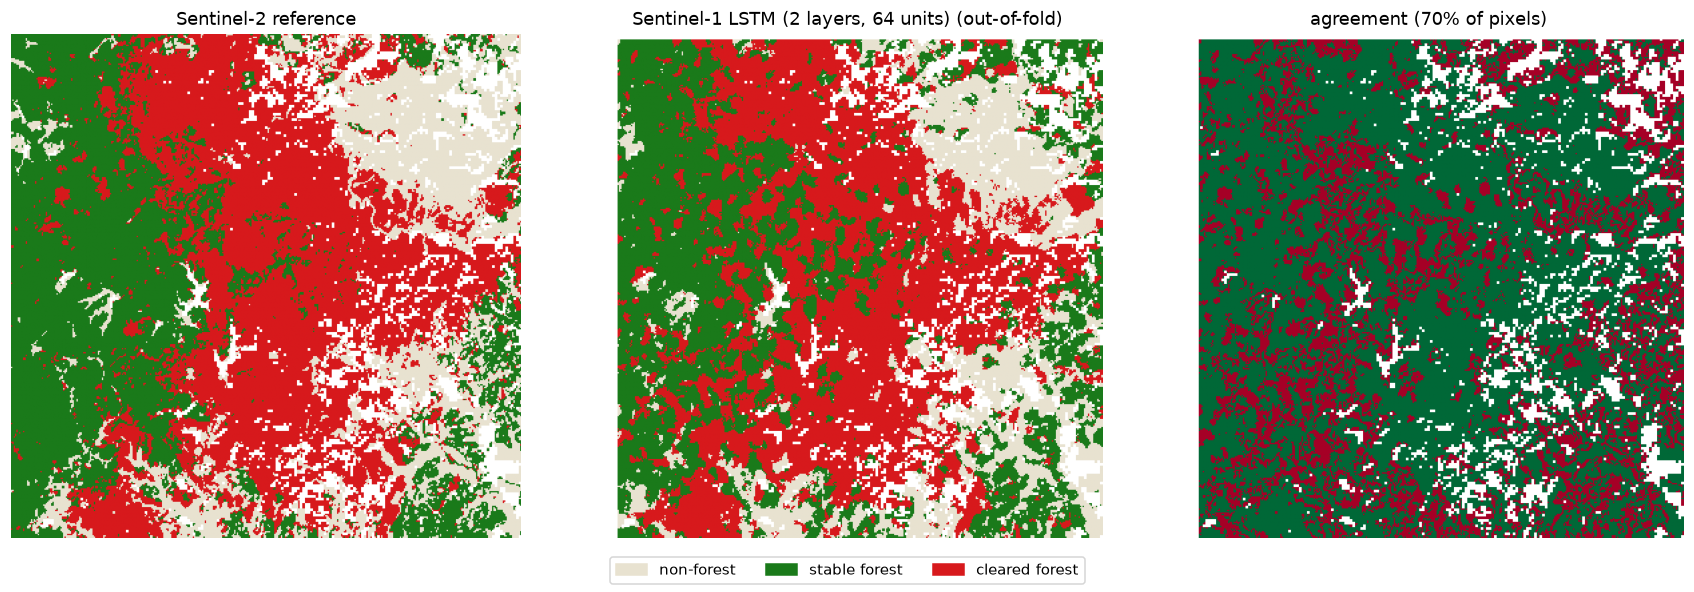

accuracy by distance from a reference class boundary:
                                   mean   size
distance to a class boundary (m)              
<=10                              0.570  57474
10-20                             0.754  18416
20-40                             0.828  23454
>40                               0.874  22497


In [16]:
best = models_table["kappa"].idxmax()  # the model with the best kappa
best_key = "LSTM" if best.startswith("LSTM") else best  # its key in preds
p = preds[best_key]  # its predictions
# confusion matrix with class names
cm = pd.DataFrame(confusion_matrix(y, p), index=[f"reference: {CLASSES[k]}" for k in CLASSES],
                  columns=[f"predicted: {CLASSES[k]}" for k in CLASSES])
display(cm)  # show it
users = np.diag(cm.values) / cm.values.sum(0)  # user's accuracy = correct / predicted, per class
producers = np.diag(cm.values) / cm.values.sum(1)  # producer's accuracy = correct / reference, per class
# both as a table
display(pd.DataFrame({"user's accuracy (precision)": users, "producer's accuracy (recall)": producers}, index=list(CLASSES.values())).round(3))

# cleared-forest area in the reference and in the prediction
cleared_ref, cleared_pred = (y == 2).sum() * px_ha, (p == 2).sum() * px_ha
binary_ref, binary_pred = (y == 2), (p == 2)  # cleared forest as a yes/no map
precision = (binary_ref & binary_pred).sum() / binary_pred.sum()  # precision of the cleared class
recall = (binary_ref & binary_pred).sum() / binary_ref.sum()  # recall of the cleared class
# area error, precision and recall
print(f"cleared forest: reference {cleared_ref:.0f} ha, {best} {cleared_pred:.0f} ha "
      f"({(cleared_pred - cleared_ref) / cleared_ref:+.0%}); as a yes/no map: precision {precision:.2f}, recall {recall:.2f}")

# predictions back on the image grid
pred_map = np.full(H * W, -1); pred_map[ok] = p; pred_map = pred_map.reshape(H, W)
cmap = plt.matplotlib.colors.ListedColormap(["#e8e2d0", "#1a7a1a", "#d7191c"])
fig, ax = plt.subplots(1, 3, figsize=(16, 5.2))  # three panels
# the Sentinel-2 reference
ax[0].imshow(np.where(labels >= 0, labels, np.nan), cmap=cmap, vmin=0, vmax=2); ax[0].set_title("Sentinel-2 reference")
# the Sentinel-1 prediction
ax[1].imshow(np.where(pred_map >= 0, pred_map, np.nan), cmap=cmap, vmin=0, vmax=2); ax[1].set_title(f"Sentinel-1 {best} (out-of-fold)")
agree = np.where(pred_map >= 0, (pred_map == labels).astype(float), np.nan)  # 1 where they agree
# agreement map
ax[2].imshow(agree, cmap="RdYlGn", vmin=0, vmax=1); ax[2].set_title(f"agreement ({np.nanmean(agree):.0%} of pixels)")
for a in ax:  # no axes
    a.set_axis_off()  # no axes
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in cmap.colors]  # legend boxes in the class colours
# legend, arrange and draw
fig.legend(handles, list(CLASSES.values()), loc="lower center", ncol=3); plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.show()

# where do errors fall? distance to the nearest class boundary
from scipy.ndimage import distance_transform_edt  # distance transform
edge = np.zeros_like(labels, bool)  # pixels where the reference class changes
# compare each pixel with its lower and right neighbours
edge[:-1] |= labels[:-1] != labels[1:]; edge[:, :-1] |= labels[:, :-1] != labels[:, 1:]
dist = distance_transform_edt(~edge) * RES  # distance (m) of each pixel to the nearest class boundary
# distance class and correctness of each labelled pixel
err = pd.DataFrame({"distance to a class boundary (m)": pd.cut(dist.ravel()[ok], [0, 10, 20, 40, 1e9], labels=["<=10", "10-20", "20-40", ">40"], include_lowest=True),
                    "correct": (p == y)})
print("accuracy by distance from a reference class boundary:")  # accuracy by distance
# errors concentrate near class boundaries
print(err.groupby("distance to a class boundary (m)", observed=True).correct.agg(["mean", "size"]).round(3).to_string())

**Out-of-fold LSTM results:**

- **Cleared forest:** recall 0.73, precision 0.77. The map estimates 531 ha of cleared forest
  against 556 ha in the labelled reference pixels (−4%).
- **Stable forest:** most often confused with cleared forest (8,121 pixels), which is the hardest
  distinction: forest thinned but not removed, and clearing that happened late in November.

The maps agree on 70% of pixels, and the disagreement is mostly at edges:

| Distance to a class boundary in the reference | Accuracy |
|---|---|
| Within 10 m | 0.570 |
| 10 to 20 m | 0.754 |
| 20 to 40 m | 0.828 |
| More than 40 m | 0.874 |

Part of the edge error is the reference itself (10 m mixed pixels and an NDVI threshold), and part
is the radar's own resolution (about 20 m) and the terrain displacement Step 3 could not remove.
Inside homogeneous areas the radar time series identifies clearing reliably. That happened during
the monsoon months when optical images were clouded out (Notebook 07_02_05): the 31 August, 24
September and 30 October acquisitions all fall in that gap.

## Summary and exercises

**What we did and found**

- **Data:** 19 Sentinel-1 GRD scenes of descending track 77 (3 January to 23 November 2017, VV+VH)
  were read remotely, window by window, and calibrated with each scene's own noise and calibration
  tables.
- **Step 1:** stacked on one 10 m grid, co-registered to within a pixel between dates.
- **Step 2:** the Quegan multitemporal filter raised ENL from 3.8 to 9.1 and kept edges (0.66 against
  0.68 dB/pixel); a single-date Lee filter blurred them to 0.27.
- **Step 3:** GCP geocoding placed the stack 40 m and 190 m off the ground. Registering it to Planetary
  Computer RTC removed that offset and raised classification accuracy from 0.588 to 0.679.
- **Steps 4 to 5:** the data cube in dB shows the signal. Cleared forest's VV − VH ratio rose from
  6.1 to 7.4 dB after the influx, while stable forest stayed near 6.2 dB.
- **Steps 6 to 8:** the best model, an LSTM on the smoothed time series, reached accuracy 0.704 and
  kappa 0.537 in spatial cross-validation. The from-scratch GRD chain matched the RTC product.
- **Step 9:** cleared forest was mapped with recall 0.73 and precision 0.77; its area came out at
  531 ha against 556 ha in the Sentinel-2 reference. Errors concentrate within 10 m of class
  boundaries.

**Limitations**

- **Reference:** Sentinel-2 NDVI, not field data or very-high-resolution imagery.
- **Geometry:** GCP geocoding plus a bulk shift is not full terrain correction.
- **Window:** the after period ends on 1 December, while clearing continued into 2018.

**Exercises**

1. Repeat the workflow with ascending track 41 (26 dual-pol scenes in 2017). Is the GCP offset the
   same? Does combining both tracks improve the classification?
2. Replace the boxcar inside the Quegan filter with `spatial="refined_lee"` and compare ENL, edge
   strength and the classification.
3. Extend the time series to June 2018 (as Notebook 07_02_05 does) and map *when* each pixel was
   cleared: the date of the largest drop in the Savitzky-Golay VH series.
4. Train on the northern half of the AOI and test on the southern half. How much does accuracy fall?
5. Add Sentinel-2 NDVI from the clear dates as features and compare radar-only, optical-only and
   combined models, especially for the monsoon months.

**References**

- Quegan, S. & Yu, J. J. (2001). Filtering of multichannel SAR images. *IEEE Transactions on Geoscience and Remote Sensing*, 39(11), 2373-2379.
- Small, D. (2011). Flattening gamma: Radiometric terrain correction for SAR imagery. *IEEE TGRS*, 49(8), 3081-3093.
- Reiche, J. et al. (2021). Forest disturbance alerts for the Congo Basin using Sentinel-1. *Environmental Research Letters*, 16, 024005.
- Hassan, M. M., Smith, A. C., Walker, K., Rahman, M. K. & Southworth, J. (2018). Rohingya refugee crisis and forest cover change in Teknaf, Bangladesh. *Remote Sensing*, 10(5), 689.
- Savitzky, A. & Golay, M. J. E. (1964). Smoothing and differentiation of data by simplified least squares procedures. *Analytical Chemistry*, 36(8), 1627-1639.
- Roberts, D. R. et al. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography*, 40, 913-929.
